# UK Online Retail: Sales Analysis, Customer Segmentation and SAP-Aligned Data Model

**Author:** Shirin Aghaei
**Tools:** Python (pandas, matplotlib), Google Colab

## Overview
This project analyses two years of real transaction data from a UK-based online giftware retailer. It covers data cleaning, sales analysis, cancellation analysis, RFM customer segmentation and the mapping of the cleaned data to an SAP SD (Sales and Distribution) billing structure.

All monetary values are in pounds sterling (£). This is a personal portfolio project using a public dataset.

In [36]:
import os

path = "/content/drive/MyDrive/uk_retail_project/online_retail_II.xlsx"
print("Drive connected:", os.path.exists("/content/drive/MyDrive"))
print("Folder found:", os.path.exists("/content/drive/MyDrive/uk_retail_project"))
print("File found:", os.path.exists(path))

Drive connected: True
Folder found: True
File found: True


## 1. Business Questions
1. How does monthly revenue change over time, and is there seasonality?
2. Which products and countries generate the most revenue?
3. How much revenue is lost to cancelled orders?
4. How can customers be segmented by purchasing behaviour (RFM), and how concentrated is revenue among the best customers?
5. How would this data look in an SAP SD billing structure?

In [37]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)
raw = pd.concat(sheets.values(), ignore_index=True)
raw = raw.rename(columns={"Customer ID": "CustomerID"})
raw.to_pickle(PROJECT_DIR + "raw_data.pkl")

print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 1,067,371 | Columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. Data Audit
Before cleaning, the raw data is checked for missing values, duplicates, negative quantities, non-positive prices and the date range covered.

In [38]:
audit = pd.DataFrame({
    "Missing values": raw.isna().sum(),
    "Missing (%)": raw.isna().mean() * 100,
})
display(audit)

print(f"Duplicate rows: {raw.duplicated().sum():,}")
print(f"Negative quantities: {(raw['Quantity'] < 0).sum():,}")
print(f"Zero or negative prices: {(raw['Price'] <= 0).sum():,}")
print(f"Date range: {raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}")

,Missing values,Missing (%)
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
CustomerID,243007,22.77
Country,0,0.00


Duplicate rows: 34,335
Negative quantities: 22,950
Zero or negative prices: 6,207
Date range: 01 Dec 2009 to 09 Dec 2011


## 3. Data Cleaning
The following rules were applied, in order:
1. Exact duplicate rows were removed.
2. Non-product stock codes (postage, manual adjustments, bank charges, fees, test codes and gift vouchers) were removed because they do not represent merchandise sales.
3. Cancelled invoices (invoice numbers starting with "C") were separated for a dedicated cancellation analysis.
4. Rows with non-positive quantities or prices were removed.
5. Rows without a Customer ID were kept for sales analysis but excluded from customer segmentation.

A revenue column was calculated as quantity multiplied by unit price (£).

In [39]:
df = raw.copy()
log = [("Raw rows", len(df))]

df = df.drop_duplicates()
log.append(("Exact duplicate rows removed", len(df)))

df["Invoice"] = df["Invoice"].astype(str)
df["CustomerID"] = df["CustomerID"].astype("Int64")
df["StockCode"] = df["StockCode"].astype(str).str.upper().str.strip()
df["Description"] = df["Description"].astype("string").str.strip().str.upper()

non_product_codes = [
    "POST", "D", "M", "BANK CHARGES", "DOT", "CRUK", "AMAZONFEE", "B", "S",
    "ADJUST", "ADJUST2", "TEST001", "TEST002", "PADS",
]
is_non_product = df["StockCode"].isin(non_product_codes) | df["StockCode"].str.startswith("GIFT")
df = df[~is_non_product]
log.append(("Non-product codes removed", len(df)))

is_cancellation = df["Invoice"].str.startswith("C")
cancellations = df[is_cancellation].copy()
df = df[~is_cancellation]
log.append(("Cancelled invoices separated", len(df)))

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
log.append(("Invalid quantities or prices removed", len(df)))

df["Revenue"] = df["Quantity"] * df["Price"]
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

cleaning_log = pd.DataFrame(log, columns=["Step", "Rows remaining"])
cleaning_log["Rows removed"] = (
    cleaning_log["Rows remaining"].shift(1) - cleaning_log["Rows remaining"]
).fillna(0).astype(int)
display(cleaning_log)

,Step,Rows remaining,Rows removed
0,Raw rows,1067371,0
1,Exact duplicate rows removed,1033036,34335
2,Non-product codes removed,1027494,5542
3,Cancelled invoices separated,1009573,17921
4,Invalid quantities or prices removed,1003607,5966


## 4. Monthly Revenue Trend
The final month in the dataset is incomplete (the data ends part-way through December 2011), so it is excluded from trend and growth calculations to avoid a misleading drop.

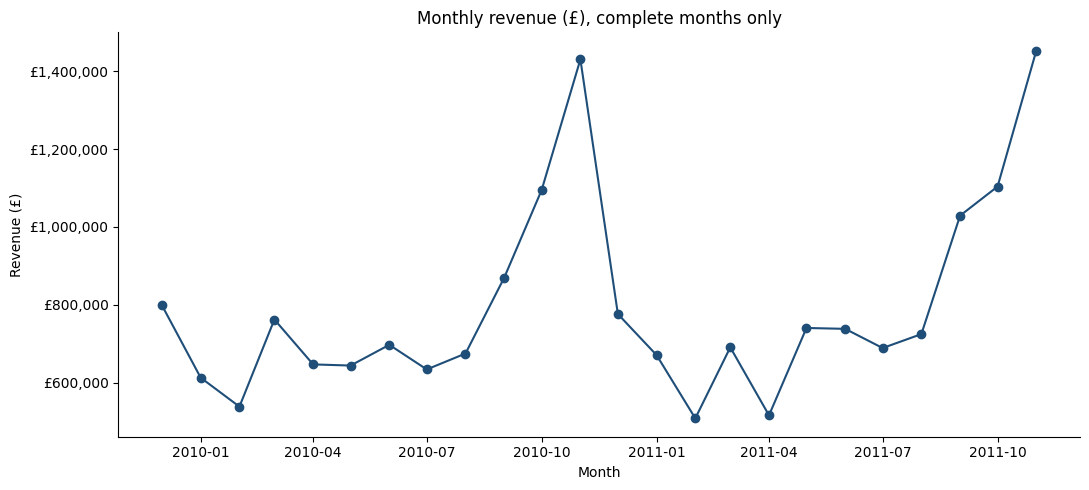

Total net revenue: £19,657,288
Peak month: November 2011 (£1,453,266)
Lowest complete month: February 2011 (£508,015)
Year-on-year change (Dec 2010 to Nov 2011 vs Dec 2009 to Nov 2010): +2.5%


In [40]:
monthly = df.groupby("InvoiceMonth")["Revenue"].sum()
last_date = df["InvoiceDate"].max()
monthly_complete = monthly.iloc[:-1] if last_date.day < last_date.days_in_month else monthly

fig, ax = plt.subplots()
ax.plot(monthly_complete.index, monthly_complete.values, marker="o", color="#1f4e79")
ax.yaxis.set_major_formatter(gbp_axis)
ax.set_title("Monthly revenue (£), complete months only")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig(IMG_DIR + "01_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

total_revenue = df["Revenue"].sum()
peak_month, peak_value = monthly_complete.idxmax(), monthly_complete.max()
low_month, low_value = monthly_complete.idxmin(), monthly_complete.min()

yoy = None
if len(monthly_complete) == 24:
    yoy = monthly_complete.iloc[12:].sum() / monthly_complete.iloc[:12].sum() - 1

print(f"Total net revenue: £{total_revenue:,.0f}")
print(f"Peak month: {peak_month:%B %Y} (£{peak_value:,.0f})")
print(f"Lowest complete month: {low_month:%B %Y} (£{low_value:,.0f})")
if yoy is not None:
    print(f"Year-on-year change (Dec 2010 to Nov 2011 vs Dec 2009 to Nov 2010): {yoy:+.1%}")

## 5. Top Products and Countries

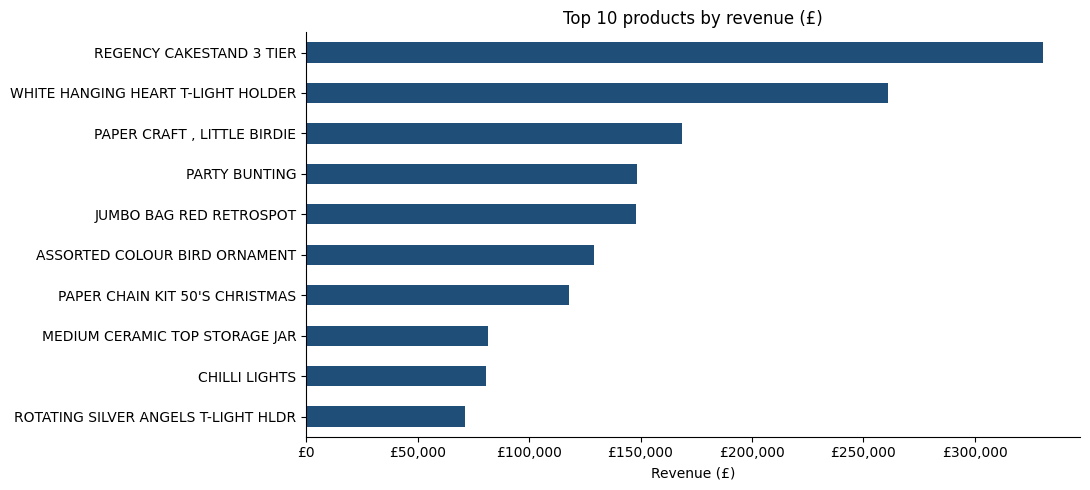

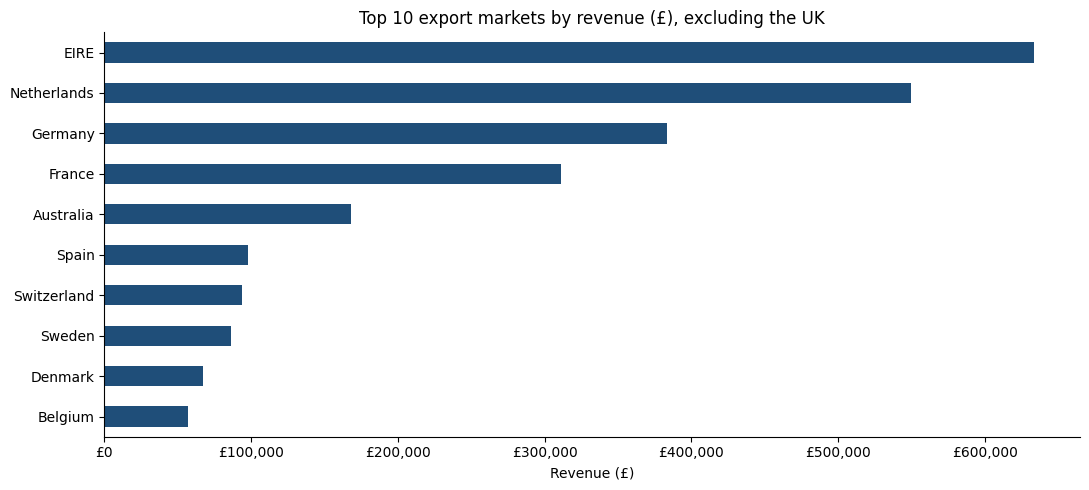

Top 10 products generate 7.8% of revenue.
The UK generates 85.5% of revenue.
Largest export market: EIRE (£633,269).


In [41]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_products_share = top_products.sum() / total_revenue

fig, ax = plt.subplots()
top_products.sort_values().plot(kind="barh", ax=ax, color="#1f4e79")
ax.xaxis.set_major_formatter(gbp_axis)
ax.set_title("Top 10 products by revenue (£)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG_DIR + "02_top_products.png", dpi=150, bbox_inches="tight")
plt.show()

country_revenue = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country_revenue.get("United Kingdom", 0) / total_revenue
export_countries = country_revenue.drop(labels=["United Kingdom"], errors="ignore")
top_export_countries = export_countries.head(10)

fig, ax = plt.subplots()
top_export_countries.sort_values().plot(kind="barh", ax=ax, color="#1f4e79")
ax.xaxis.set_major_formatter(gbp_axis)
ax.set_title("Top 10 export markets by revenue (£), excluding the UK")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG_DIR + "03_top_export_markets.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top 10 products generate {top_products_share:.1%} of revenue.")
print(f"The UK generates {uk_share:.1%} of revenue.")
print(f"Largest export market: {export_countries.index[0]} (£{export_countries.iloc[0]:,.0f}).")

## 6. Cancellation Analysis
Cancelled invoices are measured by count and by value (£) relative to completed sales.

In [42]:
cancelled_invoices = cancellations["Invoice"].nunique()
sold_invoices = df["Invoice"].nunique()
cancellation_rate = cancelled_invoices / (cancelled_invoices + sold_invoices)
cancelled_value = (cancellations["Quantity"].abs() * cancellations["Price"]).sum()
cancelled_value_share = cancelled_value / total_revenue

print(f"Completed invoices: {sold_invoices:,}")
print(f"Cancelled invoices: {cancelled_invoices:,} ({cancellation_rate:.1%} of all invoices)")
print(f"Value of cancelled orders: £{cancelled_value:,.0f} ({cancelled_value_share:.1%} of net revenue)")

Completed invoices: 39,523
Cancelled invoices: 7,409 (15.8% of all invoices)
Value of cancelled orders: £716,716 (3.6% of net revenue)


## 7. Customer Segmentation (RFM)
RFM scores each customer on three measures:
- **Recency:** days since the last purchase (lower is better)
- **Frequency:** number of distinct invoices
- **Monetary:** total spend (£)

Each measure is scored from 1 to 5 using quintiles, and the three scores are added together (range 3 to 15). Segments: Champions (13 to 15), Loyal (10 to 12), Potential (7 to 9), At Risk (5 to 6) and Lost (3 to 4). Only transactions with a Customer ID can be included.

,Customers,Revenue_GBP,Avg_spend_GBP,Avg_recency_days,Customer share (%),Revenue share (%)
Segment,,,,,,
Champions,1285,"12,290,666.25","9,564.72",25.57,21.95,71.95
Loyal,1355,"3,069,550.86","2,265.35",96.33,23.15,17.97
Potential,1447,"1,192,966.80",824.44,200.22,24.72,6.98
At Risk,966,"369,803.54",382.82,318.38,16.50,2.16
Lost,800,"158,141.27",197.68,514.24,13.67,0.93


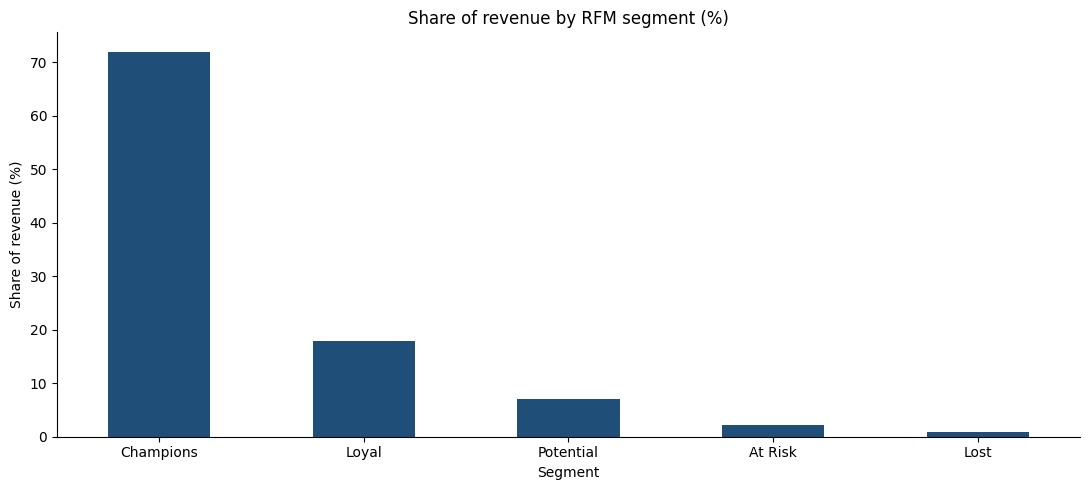

Identified customers: 5,853
Revenue from transactions without a Customer ID: 13.1%
The top 20% of identified customers generate 77.2% of identified revenue.


In [43]:
unattributed_share = df.loc[df["CustomerID"].isna(), "Revenue"].sum() / total_revenue

rfm_data = df.dropna(subset=["CustomerID"]).copy()
rfm_data["CustomerID"] = rfm_data["CustomerID"].astype(int)
snapshot_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["Score"] = rfm["R"] + rfm["F"] + rfm["M"]

def assign_segment(score):
    if score >= 13:
        return "Champions"
    if score >= 10:
        return "Loyal"
    if score >= 7:
        return "Potential"
    if score >= 5:
        return "At Risk"
    return "Lost"

rfm["Segment"] = rfm["Score"].apply(assign_segment)

segment_order = ["Champions", "Loyal", "Potential", "At Risk", "Lost"]
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Revenue_GBP=("Monetary", "sum"),
    Avg_spend_GBP=("Monetary", "mean"),
    Avg_recency_days=("Recency", "mean"),
).reindex(segment_order)
segment_summary["Customer share (%)"] = segment_summary["Customers"] / segment_summary["Customers"].sum() * 100
segment_summary["Revenue share (%)"] = segment_summary["Revenue_GBP"] / segment_summary["Revenue_GBP"].sum() * 100
display(segment_summary)

fig, ax = plt.subplots()
segment_summary["Revenue share (%)"].plot(kind="bar", ax=ax, color="#1f4e79")
ax.set_title("Share of revenue by RFM segment (%)")
ax.set_xlabel("Segment")
ax.set_ylabel("Share of revenue (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG_DIR + "04_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

cust_rev = rfm["Monetary"].sort_values(ascending=False)
top20_share = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()

champions_customer_share = segment_summary.loc["Champions", "Customer share (%)"]
champions_revenue_share = segment_summary.loc["Champions", "Revenue share (%)"]
at_risk_customers = int(segment_summary.loc["At Risk", "Customers"])
at_risk_revenue = segment_summary.loc["At Risk", "Revenue_GBP"]

print(f"Identified customers: {len(rfm):,}")
print(f"Revenue from transactions without a Customer ID: {unattributed_share:.1%}")
print(f"The top 20% of identified customers generate {top20_share:.1%} of identified revenue.")

## 8. SAP-Aligned Data Model
To show how this retail data would look in an SAP environment, the cleaned transactions were restructured into tables that follow SAP SD (Sales and Distribution) billing naming conventions. **This is a structural mapping of a public dataset. No live SAP system was used.**

| Dataset field | SAP table | SAP field | Meaning |
|---|---|---|---|
| Invoice | VBRK / VBRP | VBELN | Billing document number |
| InvoiceDate | VBRK | FKDAT | Billing date |
| CustomerID | VBRK / KNA1 | KUNAG / KUNNR | Sold-to party / customer number |
| Country | KNA1 | LAND1 | Customer country (country name used here, not an ISO key) |
| StockCode | VBRP / MAKT | MATNR | Material number |
| Description | VBRP / MAKT | ARKTX / MAKTX | Item short text / material description |
| Quantity | VBRP | FKIMG | Billed quantity |
| Price | VBRP | NETPR | Net price per unit |
| Revenue | VBRP / VBRK | NETWR | Net value (item level and document level) |
| Constant "GBP" | VBRP / VBRK | WAERK | Document currency |

Tables created: **VBRK** (billing header), **VBRP** (billing items), **KNA1** (customer master) and **MAKT** (material descriptions). A reconciliation check confirms that item-level values equal header-level values.

In [44]:
sap = df.copy()
sap["WAERK"] = "GBP"
sap = sap.sort_values(["Invoice", "InvoiceDate"])
sap["POSNR"] = (sap.groupby("Invoice").cumcount() + 1) * 10

vbrp = sap.rename(columns={
    "Invoice": "VBELN", "StockCode": "MATNR", "Description": "ARKTX",
    "Quantity": "FKIMG", "Price": "NETPR", "Revenue": "NETWR",
})[["VBELN", "POSNR", "MATNR", "ARKTX", "FKIMG", "NETPR", "NETWR", "WAERK"]]

vbrk = (
    sap.groupby("Invoice")
    .agg(FKDAT=("InvoiceDate", "min"), KUNAG=("CustomerID", "first"),
         NETWR=("Revenue", "sum"), WAERK=("WAERK", "first"))
    .reset_index()
    .rename(columns={"Invoice": "VBELN"})
)

kna1 = (
    sap.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(LAND1=("Country", "first"))
    .reset_index()
    .rename(columns={"CustomerID": "KUNNR"})
)

makt = (
    sap.groupby("StockCode")
    .agg(MAKTX=("Description", lambda x: x.mode().iloc[0] if not x.mode().empty else ""))
    .reset_index()
    .rename(columns={"StockCode": "MATNR"})
)

reconciled = round(vbrp["NETWR"].sum(), 2) == round(vbrk["NETWR"].sum(), 2)
print(f"VBRK: {len(vbrk):,} | VBRP: {len(vbrp):,} | KNA1: {len(kna1):,} | MAKT: {len(makt):,}")
print(f"Reconciliation check (item values equal header values): {reconciled}")

vbrk.to_csv(OUTPUT_DIR + "sap_vbrk.csv", index=False)
vbrp.to_csv(OUTPUT_DIR + "sap_vbrp.csv", index=False)
kna1.to_csv(OUTPUT_DIR + "sap_kna1.csv", index=False)
makt.to_csv(OUTPUT_DIR + "sap_makt.csv", index=False)
rfm.reset_index().to_csv(OUTPUT_DIR + "rfm_customers.csv", index=False)

display(vbrk.head(3))
display(vbrp.head(3))

VBRK: 39,523 | VBRP: 1,003,607 | KNA1: 5,853 | MAKT: 4,725
Reconciliation check (item values equal header values): True


,VBELN,FKDAT,KUNAG,NETWR,WAERK
0,489434,2009-12-01 07:45:00,13085,505.30,GBP
1,489435,2009-12-01 07:46:00,13085,145.80,GBP
2,489436,2009-12-01 09:06:00,13078,630.33,GBP


,VBELN,POSNR,MATNR,ARKTX,FKIMG,NETPR,NETWR,WAERK
0,489434,10,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.40,GBP
1,489434,20,79323P,PINK CHERRY LIGHTS,12,6.75,81.00,GBP
2,489434,30,79323W,WHITE CHERRY LIGHTS,12,6.75,81.00,GBP


In [45]:
lines = [
    f"- Data: {len(raw):,} raw transaction lines; {len(df):,} valid sales lines after cleaning "
    f"({raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}).",
    f"- Total net revenue was £{total_revenue:,.0f} across {sold_invoices:,} invoices.",
    f"- Revenue peaked in {peak_month:%B %Y} (£{peak_value:,.0f}); the lowest complete month was "
    f"{low_month:%B %Y} (£{low_value:,.0f}).",
]
if yoy is not None:
    lines.append(f"- Revenue for December 2010 to November 2011 was {yoy:+.1%} compared with "
                 f"December 2009 to November 2010 (complete months only).")
lines += [
    f"- The top 10 products generated {top_products_share:.1%} of revenue.",
    f"- The UK accounted for {uk_share:.1%} of revenue; the largest export market was "
    f"{export_countries.index[0]} (£{export_countries.iloc[0]:,.0f}).",
    f"- {cancellation_rate:.1%} of invoices were cancellations, worth £{cancelled_value:,.0f} "
    f"({cancelled_value_share:.1%} of net revenue).",
    f"- {unattributed_share:.1%} of revenue came from transactions without a Customer ID and was excluded from segmentation.",
    f"- Across {len(rfm):,} identified customers, the Champions segment made up {champions_customer_share:.1f}% of customers "
    f"and {champions_revenue_share:.1f}% of revenue.",
    f"- {at_risk_customers:,} customers were classed as At Risk, representing £{at_risk_revenue:,.0f} of historical revenue.",
    f"- The top 20% of identified customers generated {top20_share:.1%} of identified revenue.",
]

key_findings = "\n".join(lines)
print(key_findings)

with open(OUTPUT_DIR + "key_findings.txt", "w") as f:
    f.write(key_findings)

- Data: 1,067,371 raw transaction lines; 1,003,607 valid sales lines after cleaning (01 Dec 2009 to 09 Dec 2011).
- Total net revenue was £19,657,288 across 39,523 invoices.
- Revenue peaked in November 2011 (£1,453,266); the lowest complete month was February 2011 (£508,015).
- Revenue for December 2010 to November 2011 was +2.5% compared with December 2009 to November 2010 (complete months only).
- The top 10 products generated 7.8% of revenue.
- The UK accounted for 85.5% of revenue; the largest export market was EIRE (£633,269).
- 15.8% of invoices were cancellations, worth £716,716 (3.6% of net revenue).
- 13.1% of revenue came from transactions without a Customer ID and was excluded from segmentation.
- Across 5,853 identified customers, the Champions segment made up 22.0% of customers and 72.0% of revenue.
- 966 customers were classed as At Risk, representing £369,804 of historical revenue.
- The top 20% of identified customers generated 77.2% of identified revenue.


## 9. Recommendations
Based on the segmentation and cancellation analysis, the following actions would be worth testing:
1. **Win-back campaign for At Risk customers:** target customers who previously purchased often but have not bought recently, for example with a time-limited offer.
2. **Loyalty programme for Champions and Loyal customers:** early access to new ranges or volume-based rewards to protect the most valuable revenue.
3. **Reduce cancellations:** review the products and invoices with the highest cancellation value to identify quality, description or fulfilment issues.
4. **Capture customer IDs at checkout:** a significant share of revenue cannot be linked to a customer, which limits segmentation and retention analysis.
5. **Plan stock and staffing around the seasonal peak** identified in the monthly revenue trend.

## 10. Limitations
- The data covers one retailer between December 2009 and December 2011 and may not reflect current behaviour.
- The final month is incomplete and was excluded from trend calculations.
- Transactions without a Customer ID were excluded from RFM analysis.
- RFM segment thresholds are a standard convention rather than being optimised for this business.
- Cancellations are not linked to the original invoices, so the cancellation analysis is an approximation.
- The SAP-aligned tables are a structural mapping of public data; no SAP system was connected.